In [12]:
import kagglehub

# Download latest version
path = kagglehub.competition_download('playground-series-s4e5', output_dir='data', force_download=True )

print("Path to competition files:", path)

100%|██████████| 28.0M/28.0M [00:03<00:00, 8.19MB/s]

Extracting files...


Path to competition files: data


Libraries needed

In [13]:
import pandas as pd
import os
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from statsmodels.api import OLS, add_constant, ProbPlot


### lets see data

In [14]:
df_train = pd.read_csv(os.path.join(path, 'train.csv'))
df_test = pd.read_csv(os.path.join(path, 'test.csv'))
print("---"*20)
print("Train shape:", df_train.shape)
print("Test shape:", df_test.shape)
print("---"*20)
print("Train columns:", df_train.columns)
print("Test columns:", df_test.columns)
print("---"*20)
print("Train head:\n", df_train.head())
print("Test head:\n", df_test.head())
print("---"*20)
print("Train info:\n", df_train.info())
print("Test info:\n", df_test.info())
print("---"*20)
print("Train describe:\n", df_train.describe())
print("---"*20)

------------------------------------------------------------
Train shape: (1117957, 22)
Test shape: (745305, 21)
------------------------------------------------------------
Train columns: Index(['id', 'MonsoonIntensity', 'TopographyDrainage', 'RiverManagement',
       'Deforestation', 'Urbanization', 'ClimateChange', 'DamsQuality',
       'Siltation', 'AgriculturalPractices', 'Encroachments',
       'IneffectiveDisasterPreparedness', 'DrainageSystems',
       'CoastalVulnerability', 'Landslides', 'Watersheds',
       'DeterioratingInfrastructure', 'PopulationScore', 'WetlandLoss',
       'InadequatePlanning', 'PoliticalFactors', 'FloodProbability'],
      dtype='str')
Test columns: Index(['id', 'MonsoonIntensity', 'TopographyDrainage', 'RiverManagement',
       'Deforestation', 'Urbanization', 'ClimateChange', 'DamsQuality',
       'Siltation', 'AgriculturalPractices', 'Encroachments',
       'IneffectiveDisasterPreparedness', 'DrainageSystems',
       'CoastalVulnerability', 'Landsli

### lets train the regression

In [15]:
X = df_train.drop(columns=['FloodProbability'])
Y = df_train['FloodProbability']

train_X, test_X ,train_y, test_y = train_test_split(X, Y, test_size=0.2, random_state=42)

ml_model = LinearRegression()
ml_model.fit(train_X, train_y)

ols_model = OLS(train_y, add_constant(train_X)).fit()

In [16]:
print(ols_model.params)

const                             -5.332708e-02
id                                 1.514721e-12
MonsoonIntensity                   5.613008e-03
TopographyDrainage                 5.645112e-03
RiverManagement                    5.662407e-03
Deforestation                      5.681075e-03
Urbanization                       5.659366e-03
ClimateChange                      5.658753e-03
DamsQuality                        5.652952e-03
Siltation                          5.639752e-03
AgriculturalPractices              5.639339e-03
Encroachments                      5.645931e-03
IneffectiveDisasterPreparedness    5.639530e-03
DrainageSystems                    5.632642e-03
CoastalVulnerability               5.671065e-03
Landslides                         5.643084e-03
Watersheds                         5.647691e-03
DeterioratingInfrastructure        5.618241e-03
PopulationScore                    5.681486e-03
WetlandLoss                        5.639502e-03
InadequatePlanning                 5.612

In [17]:
ols_model.summary2()

<class 'statsmodels.iolib.summary2.Summary'>
"""
                         Results: Ordinary least squares
=================================================================================
Model:                   OLS                 Adj. R-squared:        0.845        
Dependent Variable:      FloodProbability    AIC:                   -4450908.5067
Date:                    2026-11-11 19:34    BIC:                   -4450651.0216
No. Observations:        894365              Log-Likelihood:        2.2255e+06   
Df Model:                21                  F-statistic:           2.321e+05    
Df Residuals:            894343              Prob (F-statistic):    0.00         
R-squared:               0.845               Scale:                 0.00040383   
---------------------------------------------------------------------------------
                                 Coef.  Std.Err.     t     P>|t|   [0.025  0.975]
---------------------------------------------------------------------------------
const                           -0.0533   0.0003 -208.1030 0.0000 -0.0538 -0.0528
id                               0.0000   0.0000    0.0230 0.9816 -0.0000  0.0000
MonsoonIntensity                 0.0056   0.0000  543.0174 0.0000  0.0056  0.0056
TopographyDrainage               0.0056   0.0000  555.4211 0.0000  0.0056  0.0057
RiverManagement                  0.0057   0.0000  551.4827 0.0000  0.0056  0.0057
Deforestation                    0.0057   0.0000  547.4026 0.0000  0.0057  0.0057
Urbanization                     0.0057   0.0000  553.7016 0.0000  0.0056  0.0057
ClimateChange                    0.0057   0.0000  547.1524 0.0000  0.0056  0.0057
DamsQuality                      0.0057   0.0000  553.3731 0.0000  0.0056  0.0057
Siltation                        0.0056   0.0000  547.7845 0.0000  0.0056  0.0057
AgriculturalPractices            0.0056   0.0000  547.8156 0.0000  0.0056  0.0057
Encroachments                    0.0056   0.0000  552.7576 0.0000  0.0056  0.0057
IneffectiveDisasterPreparedness  0.0056   0.0000  550.6123 0.0000  0.0056  0.0057
DrainageSystems                  0.0056   0.0000  548.2808 0.0000  0.0056  0.0057
CoastalVulnerability             0.0057   0.0000  556.4852 0.0000  0.0057  0.0057
Landslides                       0.0056   0.0000  551.2592 0.0000  0.0056  0.0057
Watersheds                       0.0056   0.0000  552.8950 0.0000  0.0056  0.0057
DeterioratingInfrastructure      0.0056   0.0000  545.3346 0.0000  0.0056  0.0056
PopulationScore                  0.0057   0.0000  554.2165 0.0000  0.0057  0.0057
WetlandLoss                      0.0056   0.0000  548.0988 0.0000  0.0056  0.0057
InadequatePlanning               0.0056   0.0000  548.6891 0.0000  0.0056  0.0056
PoliticalFactors                 0.0056   0.0000  554.3974 0.0000  0.0056  0.0057
---------------------------------------------------------------------------------
Omnibus:                 80523.034          Durbin-Watson:             2.000     
Prob(Omnibus):           0.000              Jarque-Bera (JB):          119532.450
Skew:                    0.706              Prob(JB):                  0.000     
Kurtosis:                4.103              Condition No.:             7789340   
=================================================================================
Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly
specified.
[2] The condition number is large, 7.79e+06. This might indicate
that there are strong multicollinearity or other numerical
problems.
"""

### VIF (multicollinearity check)

In [18]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# VIF on features only (exclude id and target); add a constant so VIFs are computed correctly
X_vif = add_constant(df_train.drop(columns=['id', 'FloodProbability']))
vif = pd.DataFrame({
    'feature': X_vif.columns,
    'VIF': [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])],
})
vif = vif[vif['feature'] != 'const'].sort_values('VIF', ascending=False).reset_index(drop=True)
vif

,feature,VIF
0,CoastalVulnerability,1.003687
1,Encroachments,1.003349
2,Urbanization,1.003128
3,DrainageSystems,1.003057
4,PoliticalFactors,1.003004
5,Watersheds,1.002943
6,InadequatePlanning,1.002866
7,IneffectiveDisasterPreparedness,1.002712
8,PopulationScore,1.002549
9,WetlandLoss,1.002540


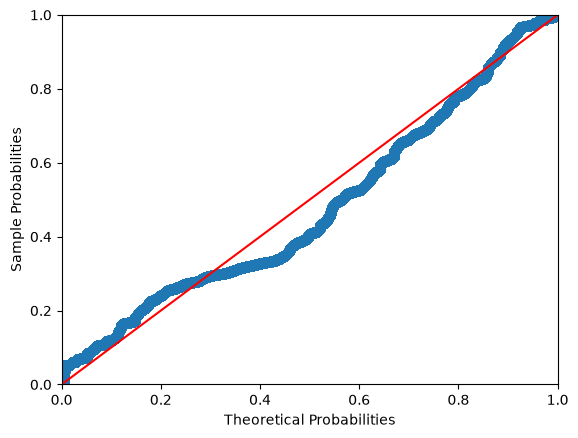

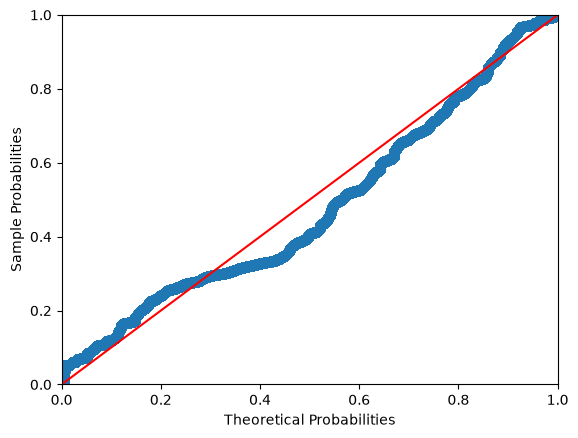

In [24]:
propplot = ProbPlot(ols_model.resid, fit=True)  # fit=True: compare against N(mean, std) of residuals, not N(0,1)
propplot.ppplot(line='45')


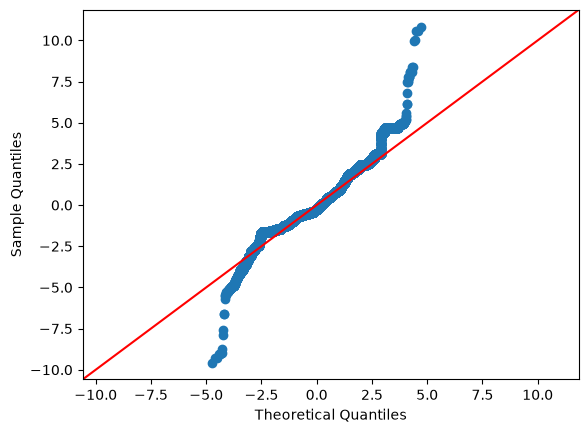

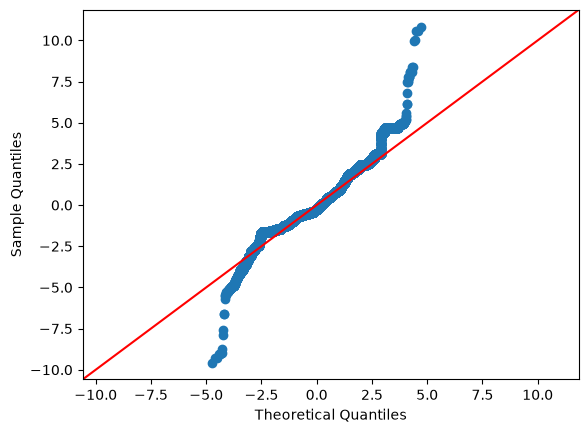

In [25]:
# Q-Q plot: residual quantiles vs fitted normal quantiles (tails show up more clearly than in P-P)
propplot.qqplot(line='45')

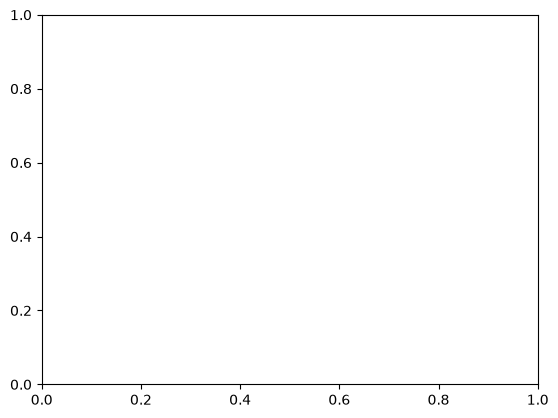

In [ ]:
# from statsmodels.graphics.regressionplots import influence_plot
# influence_plot(ols_model, criterion="cooks")  # criterion="cooks" shows Cook's distance contours

In [28]:
pred_y = ml_model.predict(test_X)
pred_y

array([0.53392548, 0.58491114, 0.52256976, ..., 0.53390792, 0.49426442,
       0.50589005], shape=(223592,))

In [30]:
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np
np.sqrt(mean_squared_error(test_y, pred_y))

np.float64(0.020080003249804697)

In [31]:
r2_score(test_y, pred_y)

0.8448773580510154